In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

df = sns.load_dataset('titanic')
print(f'Размер датасета: {df.shape}')
print(df[['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare']].head())


Размер датасета: (891, 15)
   survived  pclass     sex   age  sibsp  parch     fare
0         0       3    male  22.0      1      0   7.2500
1         1       1  female  38.0      1      0  71.2833
2         1       3  female  26.0      0      0   7.9250
3         1       1  female  35.0      1      0  53.1000
4         0       3    male  35.0      0      0   8.0500


Информация о столбцах и пропусках:
survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
dtype: int64

Описательная статистика:
         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200


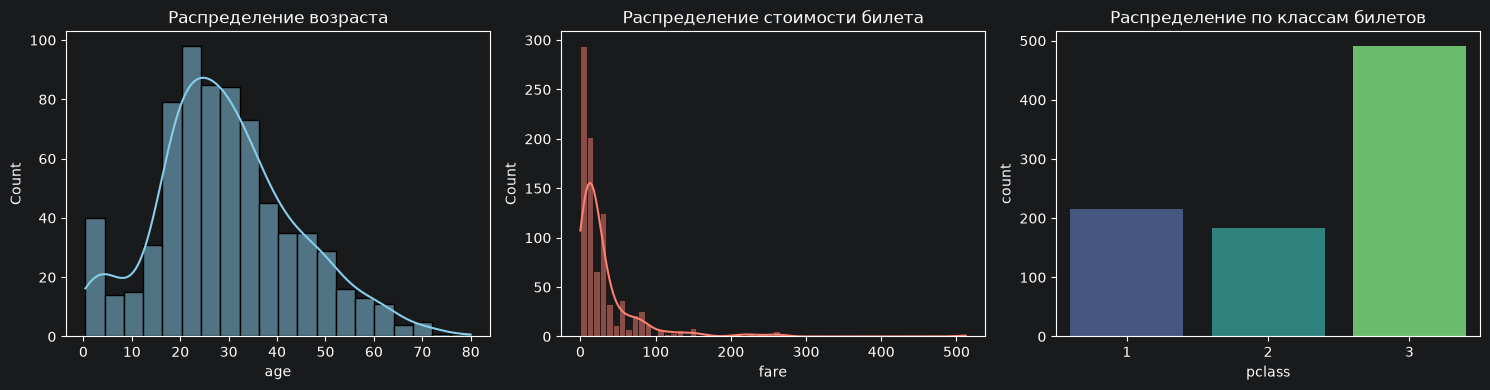

In [9]:
cols = ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare']
data = df[cols].copy()

print('Информация о столбцах и пропусках:')
print(data.isnull().sum())

print('\nОписательная статистика:')
print(data.describe())

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data['age'].dropna(), kde=True, ax=ax1, color='skyblue')
ax1.set_title('Распределение возраста')

sns.histplot(data['fare'], kde=True, ax=ax2, color='salmon')
ax2.set_title('Распределение стоимости билета')

sns.countplot(x='pclass', data=data, ax=ax3, palette='viridis')
ax3.set_title('Распределение по классам билетов')

plt.tight_layout()
plt.show()



In [4]:
data['age'] = data['age'].fillna(data['age'].median())
data['fare'] = data['fare'].fillna(data['fare'].median())

data['family_size'] = data['sibsp'] + data['parch'] + 1
data['sex_encoded'] = data['sex'].map({'male': 0, 'female': 1})

y_survived = data['survived'].copy()

feature_cols = ['pclass', 'sex_encoded', 'age', 'family_size', 'fare']
X_raw = data[feature_cols].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print('Признаки после обработки и масштабирования (первые 5 строк):')
print(pd.DataFrame(X_scaled, columns=feature_cols).head())


Признаки после обработки и масштабирования (первые 5 строк):
     pclass  sex_encoded       age  family_size      fare
0  0.827377    -0.737695 -0.565736     0.059160 -0.502445
1 -1.566107     1.355574  0.663861     0.059160  0.786845
2  0.827377     1.355574 -0.258337    -0.560975 -0.488854
3 -1.566107     1.355574  0.433312     0.059160  0.420730
4  0.827377    -0.737695  0.433312    -0.560975 -0.486337


In [10]:
results = []

for k in range(2, 7):
  km = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = km.fit_predict(X_scaled)
  sil = silhouette_score(X_scaled, labels)
  db = davies_bouldin_score(X_scaled, labels)
  results.append({
      'Метод': 'K-Means',
      'Параметры': f'n_clusters={k}',
      'Кластеров': k,
      'Silhouette (выше=лучше)': round(sil, 4),
      'Davies-Bouldin (ниже=лучше)': round(db, 4),
  })

for k in range(2, 7):
  for link in ('ward', 'complete'):
    agg = AgglomerativeClustering(n_clusters=k, linkage=link)
    labels = agg.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    results.append({
        'Метод': 'Agglomerative',
        'Параметры': f'n_clusters={k}, linkage={link}',
        'Кластеров': k,
        'Silhouette (выше=лучше)': round(sil, 4),
        'Davies-Bouldin (ниже=лучше)': round(db, 4),
    })

for eps in (0.8, 1.0, 1.2, 1.5):
  for ms in (5, 10):
    dbscan = DBSCAN(eps=eps, min_samples=ms)
    labels = dbscan.fit_predict(X_scaled)
    unique_clusters = set(labels) - {-1}
    if len(unique_clusters) >= 2:
      mask = labels != -1
      sil = silhouette_score(X_scaled[mask], labels[mask])
      db = davies_bouldin_score(X_scaled[mask], labels[mask])
      results.append({
          'Метод': 'DBSCAN',
          'Параметры': f'eps={eps}, min_samples={ms}',
          'Кластеров': len(unique_clusters),
          'Silhouette (выше=лучше)': round(sil, 4),
          'Davies-Bouldin (ниже=лучше)': round(db, 4),
      })

results_df = pd.DataFrame(results).sort_values(
    by='Silhouette (выше=лучше)', ascending=False
).reset_index(drop=True)
print('--- Сравнение моделей кластеризации ---')
print(results_df.to_string(index=False))


--- Сравнение моделей кластеризации ---
        Метод                      Параметры  Кластеров  Silhouette (выше=лучше)  Davies-Bouldin (ниже=лучше)
Agglomerative n_clusters=2, linkage=complete          2                   0.5626                       0.8131
      K-Means                   n_clusters=6          6                   0.4198                       1.0216
      K-Means                   n_clusters=5          5                   0.4112                       1.0560
       DBSCAN        eps=0.8, min_samples=10          7                   0.3882                       1.2054
      K-Means                   n_clusters=4          4                   0.3813                       1.0532
Agglomerative     n_clusters=5, linkage=ward          5                   0.3694                       1.1015
       DBSCAN        eps=1.0, min_samples=10          8                   0.3678                       1.1867
Agglomerative     n_clusters=4, linkage=ward          4                   0.3654

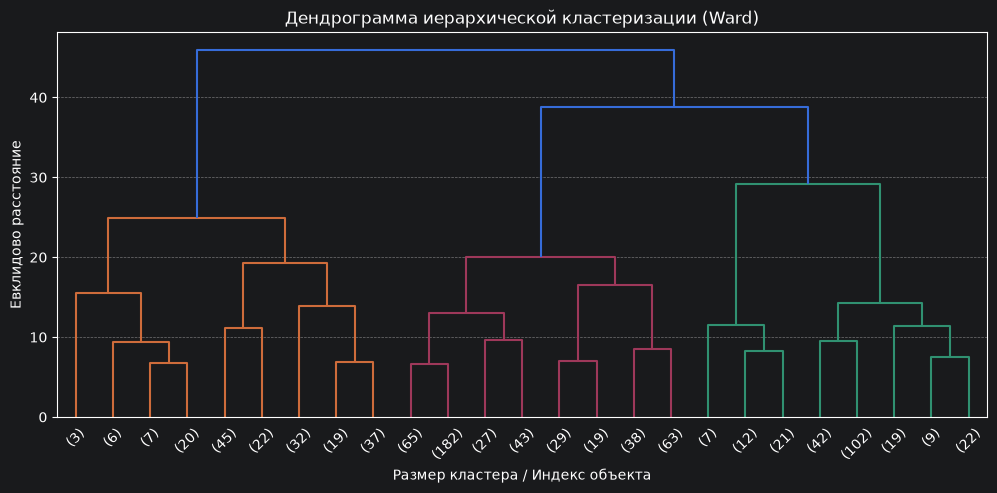

In [7]:
plt.figure(figsize=(12, 5))
Z = linkage(X_scaled, method='ward')
dendrogram(Z, truncate_mode='lastp', p=25, leaf_rotation=45, leaf_font_size=10)
plt.title('Дендрограмма иерархической кластеризации (Ward)')
plt.xlabel('Размер кластера / Индекс объекта')
plt.ylabel('Евклидово расстояние')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()
